# DSMarket — Segmentación de productos (Tarea 2)

**De:** Nicole, Data Science
**Para:** Joelle (Marketing Manager), Michelle (Chief Digital Officer)

Joelle pidió dos cosas:

1. **Agrupar productos que se comporten de manera similar**, para evaluar las campañas por grupo y no producto a producto. Preguntó cuántos grupos usar: ¿5, 10 o 20?
2. Saber si **un enfoque parecido sirve para comparar tiendas**.

Este notebook responde a las dos:

- Para los productos usamos **K-Means** y elegimos el número de grupos con el **método del codo** (probando de 2 a 14 grupos), apoyado en la **silueta**. El resultado es **una única segmentación** y cada grupo recibe un nombre que dice qué tipo de producto contiene.
- Para las tiendas **no aplicamos un algoritmo de agrupamiento**: con solo 10 tiendas, las comparamos directamente. La sección 5 explica por qué.

Parte de las mismas fuentes y decisiones de limpieza del EDA (`01_EDA_DSMarket.ipynb`, sección 6).

## 1. Configuración e imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns
from sklearn.preprocessing import StandardScaler, RobustScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA
from scipy.spatial.distance import cdist
import os

pd.set_option('display.max_columns', 50)
pd.set_option('display.width', 200)
RANDOM_STATE = 42
%matplotlib inline

## 2. Paleta de marca DSMarket

Misma paleta validada del EDA (sección 2 de `01_EDA_DSMarket.ipynb`), repetida aquí para que el notebook se pueda ejecutar por separado.

In [2]:
DSMARKET_NAVY = "#0a2a5c"
DSMARKET_BLUE = "#2a78d6"
DSMARKET_GOLD = "#eda100"
DSMARKET_GREEN = "#6a9f1f"

DSMARKET_BLUE_RAMP = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#2a78d6", "#1c5cab", "#0d366b"]
dsmarket_blues_cmap = LinearSegmentedColormap.from_list("dsmarket_blues", DSMARKET_BLUE_RAMP)
DIVERGENTE = LinearSegmentedColormap.from_list("dsmarket_div", [DSMARKET_GOLD, "#ffffff", DSMARKET_BLUE])

# un color por grupo de producto (6 grupos)
CLUSTER_PALETTE = [DSMARKET_BLUE, DSMARKET_GREEN, DSMARKET_NAVY, DSMARKET_GOLD, "#8a5fd6", "#d65f8a"]

sns.set_theme(style="whitegrid", rc={
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#0b0b0b", "text.color": "#0b0b0b",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "grid.color": "#e1e0d9",
    "figure.facecolor": "white", "axes.facecolor": "white",
})
plt.rcParams["axes.titlecolor"] = DSMARKET_NAVY
plt.rcParams["axes.titleweight"] = "bold"

## 3. Carga de datos

Mismas decisiones que en el EDA: se descartan las filas de `item_prices.csv` sin `yearweek`. Las 1.913 columnas de días se guardan como `int16` (el máximo vendido en un día es 763), lo que reduce la memoria a la cuarta parte.

El día de la semana se obtiene **de la fecha** (`dt.weekday`, 0 = lunes), no de la columna `weekday_int` del calendario, que numera la semana de sábado (1) a viernes (7).

In [3]:
DATA_DIR = "data_dsmarket/data_dsmarket"

sales = pd.read_csv(f"{DATA_DIR}/item_sales.csv")
calendar = pd.read_csv(f"{DATA_DIR}/daily_calendar_with_events.csv")
calendar['date'] = pd.to_datetime(calendar['date'])

day_cols = [c for c in sales.columns if c.startswith('d_')]
sales[day_cols] = sales[day_cols].astype('int16')

prices = pd.read_csv(f"{DATA_DIR}/item_prices.csv")
prices_clean = prices.dropna(subset=['yearweek'])
prices_clean = prices_clean.assign(yearweek=prices_clean['yearweek'].astype(int))
del prices

dates_of_days = calendar.set_index('d')['date'].loc[day_cols]
weekdays = dates_of_days.dt.weekday.values      # 0 = lunes ... 6 = domingo
months = dates_of_days.dt.month.values
is_weekend = np.isin(weekdays, [5, 6])          # sábado y domingo
is_dec = months == 12

print(f"sales: {sales.shape} | prices_clean: {prices_clean.shape} | calendar: {calendar.shape}")

sales: (30490, 1920) | prices_clean: (6721786, 5) | calendar: (1913, 5)


## 4. Segmentación de productos

### 4.1. Variables de negocio

Igual que en la asignatura (donde los clientes de Olist se describían con variables tipo RFM), primero hay que traducir "cómo se vende un producto" a números. Para cada uno de los 3.049 productos, sumando las 10 tiendas y **contando solo desde el día de su primera venta**: muchos productos se incorporaron al catálogo a mitad del periodo, y contar los días anteriores como "días sin venta" confundiría un lanzamiento tardío con un producto de compra ocasional.

| Variable | Pregunta que responde |
|---|---|
| `log_units_dia` | ¿Cuánto vende al día desde que está a la venta? (en logaritmo, porque hay productos que venden 100 veces más que otros) |
| `cv_daily` | ¿Vende de forma estable o a saltos? (coeficiente de variación diario) |
| `zero_frac` | ¿Qué % de los días en que está a la venta no vende nada? |
| `weekend_lift` | ¿Cuánto más vende en fin de semana que entre semana? |
| `dec_lift` | ¿Cuánto más vende en diciembre que el resto del año? |
| `event_lift` | ¿Cuánto más vende en los eventos con pico (SuperBowl, Easter, Labor Day) que en un día normal? |
| `trend` | ¿Sus ventas suben o bajan con los años? |
| `avg_price` | ¿Es caro o barato? |

Dos decisiones sobre `event_lift`:
- Solo se usan los eventos que en el EDA mostraron un pico real. Navidad y Thanksgiving quedan fuera porque son días de cierre o de venta muy baja.
- Se compara con los **días sin ningún evento**, para que los días de cierre no rebajen la referencia.

La categoría y el departamento **no se usan para agrupar**: el objetivo es agrupar por comportamiento. Se usan después, en la ficha de los grupos (4.6), para describirlos y ponerles nombre.

In [4]:
item_day = sales.groupby('item')[day_cols].sum()
vals = item_day.values.astype(float)

event_series = calendar.set_index('d')['event'].loc[day_cols]
labor_days = set()                               # Labor Day: primer lunes de septiembre
for y in dates_of_days.dt.year.unique():
    d = pd.Timestamp(year=int(y), month=9, day=1)
    while d.weekday() != 0:
        d += pd.Timedelta(days=1)
    labor_days.add(d)

is_peak_event = event_series.isin(['SuperBowl', 'Easter']).values | dates_of_days.isin(labor_days).values
is_any_event = (event_series.notna().values | dates_of_days.isin(labor_days).values
                | (dates_of_days.dt.month.eq(12) & dates_of_days.dt.day.eq(25)).values)
is_normal_day = ~is_any_event

# Cada producto se mide solo desde su primera venta: antes no estaba a la venta, y contar esos
# días como "sin venta" confundiría un lanzamiento tardío con un producto de compra ocasional.
primer_dia = (vals > 0).argmax(axis=1)
activo = np.arange(vals.shape[1])[None, :] >= primer_dia[:, None]
va = np.where(activo, vals, np.nan)                 # NaN = el producto aún no estaba a la venta

def media(mascara):
    return np.nanmean(np.where(mascara[None, :], va, np.nan), axis=1)

media_dia = np.nanmean(va, axis=1)
x = np.arange(vals.shape[1])
x_c = np.where(activo, x - np.nanmean(np.where(activo, x, np.nan), axis=1, keepdims=True), np.nan)

item_feat = pd.DataFrame({
    'total_units': vals.sum(axis=1),
    'dias_activo': activo.sum(axis=1),
    'units_dia': media_dia,
    'cv_daily': np.nanstd(va, axis=1) / media_dia,
    'zero_frac': np.nansum(va == 0, axis=1) / activo.sum(axis=1),
    'weekend_lift': media(is_weekend) / media(~is_weekend),
    'dec_lift': media(is_dec) / media(~is_dec),
    'event_lift': media(is_peak_event) / media(is_normal_day),
    'trend': np.nansum(np.nan_to_num(va) * np.nan_to_num(x_c), axis=1) / np.nansum(x_c ** 2, axis=1) / media_dia,
}, index=item_day.index)
item_feat['avg_price'] = prices_clean.groupby('item')['sell_price'].mean()
item_feat['log_units_dia'] = np.log1p(item_feat['units_dia'])
item_feat['facturacion'] = item_feat['total_units'] * item_feat['avg_price']   # aproximada: unidades x precio medio
print(f"Días antes de la primera venta: {(1 - activo.mean()) * 100:.1f} % de todos los días-producto")
print(f"Productos sin ningún diciembre a la venta: {int(item_feat['dec_lift'].isna().sum())}; sin eventos: {int(item_feat['event_lift'].isna().sum())}")

item_meta = sales[['item', 'category', 'department']].drop_duplicates().set_index('item')
# un producto lanzado después del último diciembre (o de los eventos) no tiene con qué compararse: se le pone 1 (sin efecto)
item_feat[['dec_lift', 'event_lift', 'weekend_lift']] = item_feat[['dec_lift', 'event_lift', 'weekend_lift']].fillna(1.0)
item_feat = item_feat.join(item_meta).dropna(subset=['avg_price'])

CANDIDATAS = ['log_units_dia', 'cv_daily', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'trend', 'avg_price']
print(f"Productos con todas las variables: {len(item_feat)} de {sales['item'].nunique()}")
item_feat[CANDIDATAS].describe().round(2)

Días antes de la primera venta: 17.8 % de todos los días-producto
Productos sin ningún diciembre a la venta: 0; sin eventos: 0
Productos con todas las variables: 3049 de 3049


,log_units_dia,cv_daily,zero_frac,weekend_lift,dec_lift,event_lift,trend,avg_price
count,3049.00,3049.00,3049.00,3049.00,3049.00,3049.00,3049.0,3049.00
mean,2.11,0.76,0.15,1.32,0.95,1.14,0.0,5.57
std,0.92,0.27,0.14,0.13,0.32,0.28,0.0,4.54
min,0.30,0.21,0.00,0.80,0.00,0.00,-0.0,0.24
25%,1.44,0.57,0.03,1.24,0.82,0.98,-0.0,2.63
50%,1.99,0.71,0.10,1.32,0.94,1.12,-0.0,4.19
75%,2.65,0.90,0.22,1.40,1.07,1.27,0.0,7.19
max,6.26,2.69,0.80,1.91,7.66,3.66,0.0,39.49


### 4.2. Revisión de variables: ¿alguna repite información?

Si dos variables miden casi lo mismo, esa idea cuenta **doble** en la distancia que usa K-Means y desequilibra el agrupamiento. Se revisa la correlación entre las 8 candidatas.

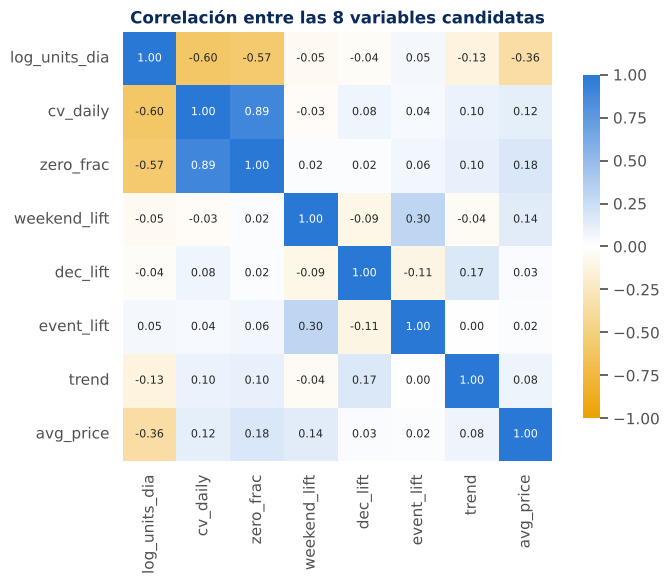

,level_0,level_1,correlacion
10,cv_daily,zero_frac,0.89
1,log_units_dia,cv_daily,-0.60
2,log_units_dia,zero_frac,-0.57
7,log_units_dia,avg_price,-0.36


In [5]:
corr = item_feat[CANDIDATAS].corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr, annot=True, fmt='.2f', cmap=DIVERGENTE, center=0, vmin=-1, vmax=1,
            square=True, cbar_kws={'shrink': 0.8}, ax=ax, annot_kws={'size': 8})
ax.set_title('Correlación entre las 8 variables candidatas')
plt.tight_layout()
plt.show()

pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack()
         .rename('correlacion').reset_index().assign(abs=lambda d: d['correlacion'].abs())
         .sort_values('abs', ascending=False).drop(columns='abs').head(4))
pares.round(2)

**Decisión: se quitan `cv_daily` y `trend`, y se agrupa con 6 variables.**

- **`cv_daily` y `zero_frac` tienen una correlación de 0,89**: miden casi lo mismo. Un producto que muchos días no vende nada es, por fuerza, un producto que vende a saltos. Se mantiene `zero_frac` porque se explica mejor a negocio ("% de días sin venta").
- **`trend` se deja fuera por otro motivo.** Medida desde el lanzamiento de cada producto ya no repite ninguna otra variable (su correlación más alta es 0,17). Pero describe el ciclo de vida del producto (si está creciendo o decayendo), no *cuándo y cómo* se compra, que es lo que necesita marketing para diseñar campañas. La tendencia ya la recoge el modelo de predicción de la Tarea 3 con sus medias móviles.

**Por qué importa medir desde el lanzamiento:** el 17,8 % de los días-producto son anteriores a la primera venta de cada producto. En una primera versión se contaban como "días sin venta", y eso hacía que `trend` y `zero_frac` tuvieran una correlación de 0,81: los dos estaban midiendo sobre todo *cuándo llegó el producto al catálogo*, no cómo se vende.

Con `cv_daily` dentro, la idea de "vende a saltos" contaría dos veces en la distancia. El resto de pares tiene correlaciones bajas, así que cada variable aporta algo propio.

In [6]:
FEAT_COLS = ['log_units_dia', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'avg_price']
print(f"Variables finales ({len(FEAT_COLS)}): {FEAT_COLS}")

Variables finales (6): ['log_units_dia', 'zero_frac', 'weekend_lift', 'dec_lift', 'event_lift', 'avg_price']


### 4.3. Escalado: StandardScaler frente a RobustScaler

K-Means usa distancias, así que todas las variables tienen que estar en la misma escala. Si no, el precio (de 0,2 a 40 $) pesaría mucho más que un ratio que va de 0 a 2.

En la asignatura se usó `RobustScaler`, que escala con la mediana y los cuantiles para reducir la influencia de los valores extremos. Aquí hay valores extremos claros, como un producto que vende 7,7 veces más en diciembre que el resto del año, así que se prueban los dos escaladores en todo el rango de K.

In [7]:
ESCALADORES = {'StandardScaler': StandardScaler(), 'RobustScaler': RobustScaler()}
K_RANGO = range(2, 15)

curvas = []
for nombre, esc in ESCALADORES.items():
    X = esc.fit_transform(item_feat[FEAT_COLS].values)
    for k in K_RANGO:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50).fit(X)
        tamanos = np.bincount(km.labels_)
        curvas.append({'escalador': nombre, 'k': k, 'inercia': km.inertia_,
                       'silueta': silhouette_score(X, km.labels_),
                       'grupo_mas_pequeno': tamanos.min()})
curvas = pd.DataFrame(curvas)
curvas.pivot(index='k', columns='escalador', values='grupo_mas_pequeno').rename_axis(columns='productos en el grupo más pequeño')

productos en el grupo más pequeño,RobustScaler,StandardScaler
k,,
2,939,1182
3,276,654
4,201,263
5,100,243
6,92,120
7,75,89
8,1,74
9,1,71
10,1,70


**Decisión: `StandardScaler`.**

`RobustScaler` hace lo contrario de lo que se busca aquí. Al escalar con la mediana y los cuantiles, los valores extremos quedan todavía más lejos del resto, y **a partir de K=8 K-Means los aísla en grupos de un solo producto**. Con `StandardScaler`, todos los grupos tienen un tamaño razonable en la zona donde se va a elegir K (entre 5 y 8 grupos, el más pequeño tiene al menos 74 productos). Un grupo de un solo producto no sirve para diseñar una campaña.

In [8]:
X_items = StandardScaler().fit_transform(item_feat[FEAT_COLS].values)
curva = curvas[curvas['escalador'] == 'StandardScaler'].set_index('k')

### 4.4. ¿Cuántos grupos? Método del codo y silueta

Es la idea central de la asignatura: se entrena K-Means con **K de 2 a 14** y se dibuja la **inercia** (la dispersión de los productos respecto al centro de su grupo). Al añadir grupos la inercia siempre baja; lo que se busca es el **codo**, el punto a partir del cual añadir más grupos apenas mejora.

Cuando la curva es suave y el codo no se ve a simple vista, se puede localizar midiendo qué punto de la curva se aleja más de la recta que une sus extremos. Como apoyo se usa la **silueta** (de -1 a 1, más alto es mejor): mide si cada producto está más cerca de su grupo que del grupo vecino.

Zona del codo (≥90 % de la distancia máxima a la recta): K = [6, 7, 8]
Dentro de esa zona, la mejor silueta es la de K = 6


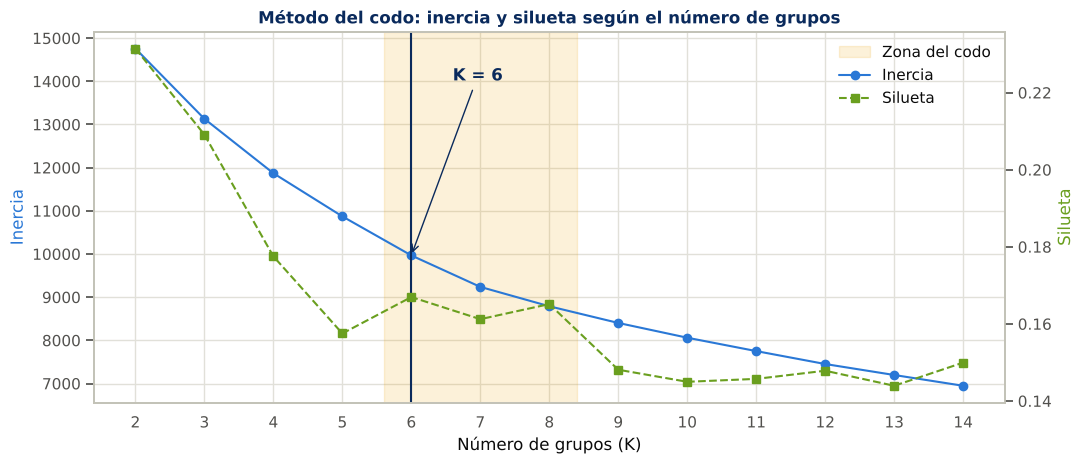

,inercia,silueta,distancia_a_la_recta,grupo_mas_pequeno
k,,,,
2,14759.259,0.231,0.000,1182
3,13131.208,0.209,0.125,654
4,11870.668,0.178,0.203,263
5,10871.128,0.158,0.248,243
6,9966.776,0.167,0.280,120
7,9237.926,0.161,0.290,89
8,8789.217,0.165,0.264,74
9,8402.935,0.148,0.230,71
10,8060.923,0.145,0.191,70


In [9]:
k_vals = curva.index.values.astype(float)
inercia = curva['inercia'].values
xn = (k_vals - k_vals.min()) / (k_vals.max() - k_vals.min())
yn = (inercia - inercia.min()) / (inercia.max() - inercia.min())
curva['distancia_a_la_recta'] = np.abs(yn - (1 - xn))      # cuanto mayor, más "codo" hay en ese punto

umbral = 0.9 * curva['distancia_a_la_recta'].max()
zona_codo = curva.index[curva['distancia_a_la_recta'] >= umbral].tolist()
K = int(curva.loc[zona_codo, 'silueta'].idxmax())
print(f"Zona del codo (≥90 % de la distancia máxima a la recta): K = {zona_codo}")
print(f"Dentro de esa zona, la mejor silueta es la de K = {K}")

fig, ax1 = plt.subplots(figsize=(11, 4.8))
ax1.axvspan(min(zona_codo) - 0.4, max(zona_codo) + 0.4, color=DSMARKET_GOLD, alpha=0.15, label='Zona del codo')
ax1.plot(curva.index, curva['inercia'], marker='o', color=DSMARKET_BLUE, label='Inercia')
ax1.set_xlabel('Número de grupos (K)')
ax1.set_ylabel('Inercia', color=DSMARKET_BLUE)
ax2 = ax1.twinx()
ax2.plot(curva.index, curva['silueta'], marker='s', linestyle='--', color=DSMARKET_GREEN, label='Silueta')
ax2.set_ylabel('Silueta', color=DSMARKET_GREEN)
ax2.grid(False)
ax1.axvline(K, color=DSMARKET_NAVY, linewidth=1.5)
ax1.annotate(f'K = {K}', xy=(K, curva.loc[K, 'inercia']), xytext=(K + 0.6, curva['inercia'].max() * 0.95),
             color=DSMARKET_NAVY, fontweight='bold', arrowprops=dict(arrowstyle='->', color=DSMARKET_NAVY))
ax1.set_xticks(list(K_RANGO))
lineas = ax1.get_legend_handles_labels(); lineas2 = ax2.get_legend_handles_labels()
ax1.legend(lineas[0] + lineas2[0], lineas[1] + lineas2[1], frameon=False, loc='upper right')
ax1.set_title('Método del codo: inercia y silueta según el número de grupos')
plt.tight_layout()
plt.show()

curva[['inercia', 'silueta', 'distancia_a_la_recta', 'grupo_mas_pequeno']].round(3)

**Decisión: K = 6.**

- **Codo:** la curva de la inercia es suave, sin un quiebre brusco (es lo habitual con datos de comportamiento, donde los productos no forman islas separadas sino un continuo). Medido de forma objetiva, la zona del codo (los puntos que más se alejan de la recta) va de **6 a 8 grupos**.
- **Silueta:** dentro de esa zona, K = 6 tiene la mejor silueta (0,167).
- **Tamaño:** el grupo más pequeño tiene 120 productos, suficiente para una campaña propia.

La silueta es más alta con 2, 3 o 4 grupos, pero esas particiones solo separan "productos que venden mucho" de "productos que venden poco": no distinguen el fin de semana, Navidad o los eventos, que es justo lo que necesita marketing. La silueta moderada (0,17) se explica por lo mismo: los productos se reparten de forma continua y los grupos tienen bordes difusos. Lo que se busca es una partición útil y estable, y eso se comprueba en el siguiente apartado.

### 4.5. Modelo final y estabilidad

Se entrena K-Means con el K elegido. Como K-Means empieza con centros al azar, se comprueba que el resultado no dependa de la suerte: se repite con 10 semillas distintas y se compara cada resultado con el primero mediante el **índice de Rand ajustado** (ARI: 1 = grupos idénticos, 0 = coincidencia al azar).

In [10]:
modelos = [KMeans(n_clusters=K, random_state=s, n_init=50).fit(X_items) for s in range(10)]
ari = [adjusted_rand_score(modelos[0].labels_, m.labels_) for m in modelos[1:]]
print(f"ARI medio entre 10 semillas: {np.mean(ari):.2f} (mínimo {np.min(ari):.2f})")

km_final = KMeans(n_clusters=K, random_state=RANDOM_STATE, n_init=50).fit(X_items)
item_feat['grupo_raw'] = km_final.labels_

ARI medio entre 10 semillas: 0.98 (mínimo 0.96)


### 4.6. Ficha de los grupos y nombres

Como en la asignatura, se resume cada grupo en una **ficha**: tamaño, valores medios de las variables usadas y, además, **variables que no se usaron para agrupar** (categoría y facturación). Estas últimas sirven para describir qué productos hay en cada grupo y ponerle un **nombre de negocio**.

Para que los nombres no dependan del número que K-Means asigna a cada grupo (que cambia según la semilla), se asignan con reglas sobre la propia ficha: el grupo con más diciembre es el de Navidad, el de precio más alto es el premium, y así sucesivamente.

In [11]:
perfil = item_feat.groupby('grupo_raw').agg(
    productos=('total_units', 'size'), unidades_medias=('units_dia', 'mean'),
    zero_frac=('zero_frac', 'mean'), weekend_lift=('weekend_lift', 'mean'), dec_lift=('dec_lift', 'mean'),
    event_lift=('event_lift', 'mean'), avg_price=('avg_price', 'mean'), facturacion=('facturacion', 'sum'))

# --- nombres por reglas sobre la ficha (independientes de la numeración de K-Means) ---
pendientes = list(perfil.index)
def tomar(col, mayor=True):
    g = perfil.loc[pendientes, col].idxmax() if mayor else perfil.loc[pendientes, col].idxmin()
    pendientes.remove(g)
    return g
asignacion = {}
asignacion[tomar('dec_lift')] = 'Temporada de Navidad'
asignacion[tomar('avg_price')] = 'Accesorios y hogar de precio alto'
asignacion[tomar('unidades_medias')] = 'Alimentación de consumo diario'
asignacion[tomar('zero_frac')] = 'Compra ocasional en fechas señaladas'
asignacion[tomar('weekend_lift')] = 'Hogar de fin de semana'
asignacion[tomar('weekend_lift')] = 'Básicos de rotación lenta'
assert not pendientes, "quedan grupos sin nombre"

# numeración final: de mayor a menor facturación
orden = perfil['facturacion'].sort_values(ascending=False).index
nuevo_id = {g: i for i, g in enumerate(orden)}
item_feat['grupo'] = item_feat['grupo_raw'].map(nuevo_id)
item_feat['nombre_grupo'] = item_feat['grupo_raw'].map(asignacion)
NOMBRES = dict(zip(item_feat['grupo'], item_feat['nombre_grupo']))
NOMBRES = {k: NOMBRES[k] for k in sorted(NOMBRES)}
for g, n in NOMBRES.items():
    print(f"Grupo {g}: {n}")

Grupo 0: Alimentación de consumo diario
Grupo 1: Hogar de fin de semana
Grupo 2: Básicos de rotación lenta
Grupo 3: Accesorios y hogar de precio alto
Grupo 4: Compra ocasional en fechas señaladas
Grupo 5: Temporada de Navidad


In [12]:
g = item_feat.groupby('grupo')
ficha = pd.DataFrame({
    'Grupo': [f'{i} · {NOMBRES[i]}' for i in sorted(NOMBRES)],
    'Productos': g.size().values,
    '% del catálogo': (g.size() / len(item_feat) * 100).values,
    '% de la facturación': (g['facturacion'].sum() / item_feat['facturacion'].sum() * 100).values,
    'Unidades por día': g['units_dia'].mean().values,
    'Días a la venta': g['dias_activo'].mean().values,
    '% días sin venta': (g['zero_frac'].mean() * 100).values,
    'Fin de semana vs. entre semana': g['weekend_lift'].mean().values,
    'Diciembre vs. resto del año': g['dec_lift'].mean().values,
    'Eventos vs. día normal': g['event_lift'].mean().values,
    'Precio medio ($)': g['avg_price'].mean().values,
}).set_index('Grupo')
categorias = pd.crosstab(item_feat['grupo'], item_feat['category'], normalize='index') * 100
categorias.index = ficha.index
categorias.columns = [f'% {c}' for c in categorias.columns]
ficha = ficha.join(categorias)

(ficha.T.style.format('{:,.2f}')
      .background_gradient(cmap=dsmarket_blues_cmap, axis=1))

Grupo,0 · Alimentación de consumo diario,1 · Hogar de fin de semana,2 · Básicos de rotación lenta,3 · Accesorios y hogar de precio alto,4 · Compra ocasional en fechas señaladas,5 · Temporada de Navidad
Productos,679.00,882.00,745.00,218.00,405.00,120.00
% del catálogo,22.27,28.93,24.43,7.15,13.28,3.94
% de la facturación,42.44,25.43,14.74,11.08,4.23,2.08
Unidades por día,37.39,8.10,6.04,4.59,2.60,5.39
Días a la venta,"1,631.93","1,574.90","1,560.83","1,484.08","1,575.57","1,450.28"
% días sin venta,5.25,9.31,12.47,17.21,38.83,31.17
Fin de semana vs. entre semana,1.29,1.42,1.21,1.35,1.34,1.31
Diciembre vs. resto del año,0.93,0.93,0.95,0.96,0.78,1.89
Eventos vs. día normal,1.12,1.27,0.96,1.10,1.26,1.01
Precio medio ($),2.62,5.22,4.91,17.44,6.13,5.37


**Los 6 grupos.** El nombre de cada grupo dice qué tipo de producto contiene. Cuando una categoría es mayoritaria, aparece en el nombre; cuando el grupo es mixto, se nombra por el momento de compra.

| Grupo | Qué productos contiene | Qué lo define |
|---|---|---|
| **0 · Alimentación de consumo diario** | 72 % alimentación, los más baratos (2,6 $) | Venden mucho (37 unidades al día entre las 10 tiendas) y casi todos los días (5 % de días sin venta). Son el **42 % de la facturación**. |
| **1 · Hogar de fin de semana** | 45 % hogar y jardín | Venden un 42 % más el fin de semana, el valor más alto de todos, y también suben en los eventos. Segundo grupo en facturación (25 %). |
| **2 · Básicos de rotación lenta** | mixto (52 % alimentación, 26 % hogar, 21 % accesorios) | Venden poco (6 unidades al día) y sin picos: son los que menos reaccionan al fin de semana, a diciembre y a los eventos. Son el 24 % del catálogo y el 15 % de la facturación. |
| **3 · Accesorios y hogar de precio alto** | 48 % accesorios + 43 % hogar | Los más caros (17,4 $ de media, más del triple que el resto). Pocas unidades, pero el 11 % de la facturación. |
| **4 · Compra ocasional en fechas señaladas** | mixto (49 % hogar, 28 % alimentación, 23 % accesorios) | El 39 % de los días en que están a la venta no venden nada, pero en SuperBowl, Easter y Labor Day venden un **26 % más** que un día normal. Son el 13 % del catálogo y solo el 4 % de la facturación. |
| **5 · Temporada de Navidad** | mixto (38 % accesorios, 35 % alimentación, 28 % hogar): mesa y regalo | En diciembre venden **casi el doble** (1,89 veces) que el resto del año. |

**Para Joelle:**
- Cada grupo pide una campaña distinta: el grupo 1 se trabaja los viernes y sábados, el grupo 4 en las fechas señaladas del calendario y el grupo 5 en diciembre.
- Para medir si una campaña ha funcionado, conviene comparar cada producto con su grupo y no con el total de la tienda: cada grupo trae ya su propio nivel "normal" de ventas y de estacionalidad.
- El grupo 4 es el candidato a revisar el surtido: ocupa el 13 % del catálogo y aporta el 4 % de la facturación.

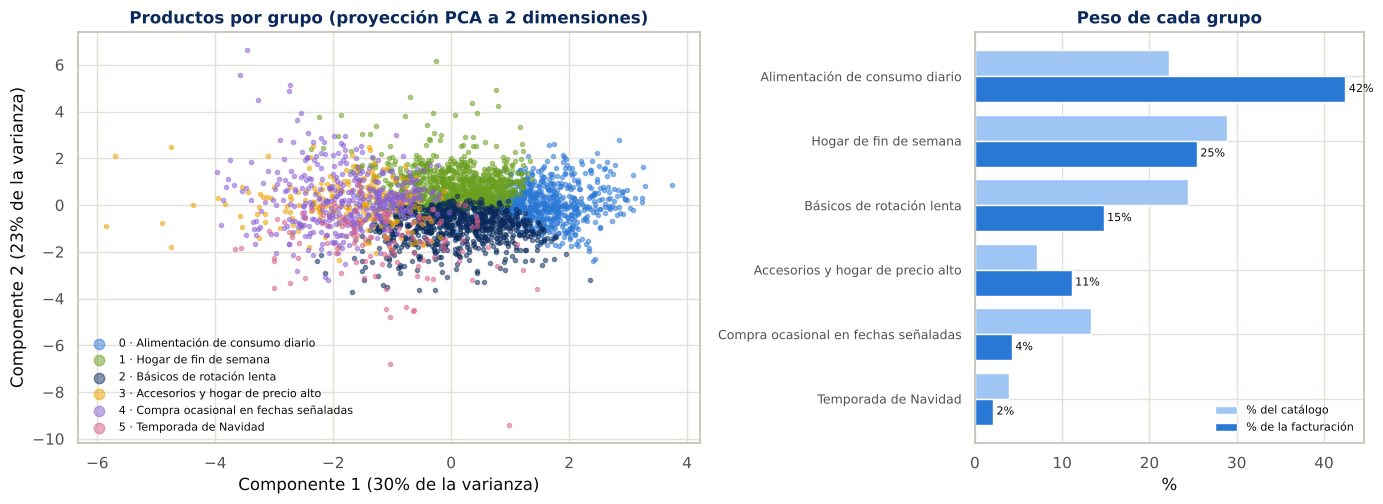

Las dos componentes resumen el 52% de la información de las 6 variables.


In [13]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
coords = pca.fit_transform(X_items)
var_exp = pca.explained_variance_ratio_

fig, axes = plt.subplots(1, 2, figsize=(14, 5.2), gridspec_kw={'width_ratios': [1.6, 1]})
ax = axes[0]
for gr in sorted(NOMBRES):
    m = (item_feat['grupo'] == gr).values
    ax.scatter(coords[m, 0], coords[m, 1], s=9, alpha=0.5, color=CLUSTER_PALETTE[gr], label=f'{gr} · {NOMBRES[gr]}')
ax.set_xlabel(f'Componente 1 ({var_exp[0]:.0%} de la varianza)')
ax.set_ylabel(f'Componente 2 ({var_exp[1]:.0%} de la varianza)')
ax.set_title('Productos por grupo (proyección PCA a 2 dimensiones)')
ax.legend(frameon=False, markerscale=2.5, fontsize=8, loc='best')

ax2 = axes[1]
tabla = ficha[['% del catálogo', '% de la facturación']].iloc[::-1]
y = np.arange(len(tabla))
ax2.barh(y + 0.2, tabla['% del catálogo'], height=0.4, color='#9ec5f4', label='% del catálogo')
ax2.barh(y - 0.2, tabla['% de la facturación'], height=0.4, color=DSMARKET_BLUE, label='% de la facturación')
ax2.set_yticks(y); ax2.set_yticklabels([t.split(' · ')[1] for t in tabla.index], fontsize=9)
for yy, v in zip(y - 0.2, tabla['% de la facturación']):
    ax2.text(v, yy, f' {v:.0f}%', va='center', fontsize=8)
ax2.set_xlabel('%')
ax2.set_title('Peso de cada grupo')
ax2.legend(frameon=False, fontsize=8, loc='lower right')
plt.tight_layout()
plt.show()
print(f"Las dos componentes resumen el {var_exp.sum():.0%} de la información de las {len(FEAT_COLS)} variables.")

### 4.7. Respuesta a Joelle: ¿5, 10 o 20 grupos?

Joelle propuso tres valores. Se comparan con el elegido por el codo:

In [14]:
extra = []
for k in [5, K, 10, 20]:
    if k in curva.index:
        r = curva.loc[k]
        extra.append({'K': k, 'silueta': r['silueta'], 'grupo más pequeño': int(r['grupo_mas_pequeno']), 'origen': 'codo' if k == K else 'propuesta de Joelle'})
    else:
        km = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=50).fit(X_items)
        extra.append({'K': k, 'silueta': silhouette_score(X_items, km.labels_),
                      'grupo más pequeño': int(np.bincount(km.labels_).min()), 'origen': 'propuesta de Joelle'})
pd.DataFrame(extra).set_index('K').round(3)

,silueta,grupo más pequeño,origen
K,,,
5,0.158,243,propuesta de Joelle
6,0.167,120,codo
10,0.145,70,propuesta de Joelle
20,0.134,1,propuesta de Joelle


**Respuesta a Joelle: 6 grupos.**

- **5 grupos** está cerca, pero junta el grupo de Navidad con otros productos y su señal se pierde.
- **10 grupos** afina algo más (separa un núcleo de eventos todavía más extremo), pero empeora la silueta (0,145) y parte los grupos grandes de alimentación y hogar en subgrupos que solo se diferencian en matices. Para planificar campañas, 6 grupos es más manejable.
- **20 grupos** deja un grupo con **un solo producto**: ya no es una segmentación, es una lista.

Además, una sola segmentación evita el problema de tener dos clasificaciones distintas del mismo producto (una con 5 grupos y otra con 10) que no encajan entre sí.

### 4.8. Un caso que ilustra el grupo de Navidad: `SUPERMARKET_3_069`

Dentro del grupo de Navidad destaca un producto con la mayor subida de diciembre de todo el catálogo.

Producto con más subida en diciembre: SUPERMARKET_3_069 (grupo 5 · Temporada de Navidad)
Vende 7.7 veces más en diciembre que el resto del año.

Sus 5 mejores días en cinco años:
2014-12-31    981
2012-12-31    906
2013-12-31    770
2015-12-31    756
2011-12-24    418


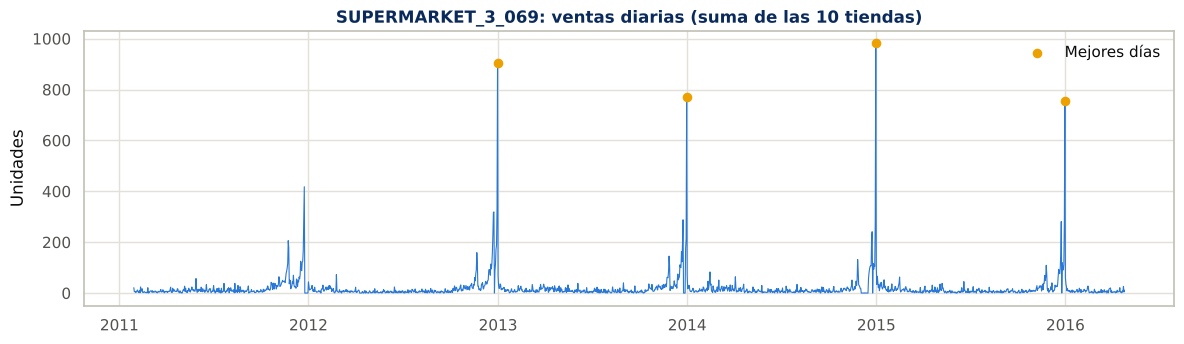

In [15]:
caso = item_feat['dec_lift'].idxmax()
print(f"Producto con más subida en diciembre: {caso} (grupo {item_feat.loc[caso, 'grupo']} · {item_feat.loc[caso, 'nombre_grupo']})")
print(f"Vende {item_feat.loc[caso, 'dec_lift']:.1f} veces más en diciembre que el resto del año.")
print()
serie = pd.Series(item_day.loc[caso].values, index=dates_of_days.values)
print("Sus 5 mejores días en cinco años:")
print(serie.sort_values(ascending=False).head(5).to_string())

fig, ax = plt.subplots(figsize=(12, 3.6))
ax.plot(serie.index, serie.values, color=DSMARKET_BLUE, linewidth=0.8)
top = serie.sort_values(ascending=False).head(4)
ax.scatter(top.index, top.values, color=DSMARKET_GOLD, zorder=3, s=35, label='Mejores días')
ax.set_title(f'{caso}: ventas diarias (suma de las 10 tiendas)')
ax.set_ylabel('Unidades')
ax.legend(frameon=False)
plt.tight_layout()
plt.show()

`SUPERMARKET_3_069` vende una mediana de 8 unidades al día entre las 10 tiendas, pero sus cuatro mejores días en cinco años son **cuatro 31 de diciembre**. Es, con toda probabilidad, un producto de Nochevieja.

Sirve para explicar el grupo de Navidad y deja dos avisos para las tareas siguientes:
- **Predicción (Tarea 3):** un modelo que no tenga en cuenta el calendario lo subestimará en diciembre.
- **Reposición (Tarea 4):** el stock de seguridad de estos productos no se puede calcular con la demanda media del año; necesitan una regla de temporada o se agotarán justo el 31.

### 4.9. Guardar la segmentación

Se guarda el grupo de cada producto para usarlo en la predicción de ventas (Tarea 3) y en la reposición (Tarea 4).

In [16]:
os.makedirs('cache_forecast', exist_ok=True)
salida = item_feat[['grupo', 'nombre_grupo']]
salida.to_csv('cache_forecast/segmentacion_productos.csv')
print(f"Guardado cache_forecast/segmentacion_productos.csv: {len(salida)} productos")
salida['nombre_grupo'].value_counts()

Guardado cache_forecast/segmentacion_productos.csv: 3049 productos


nombre_grupo
Hogar de fin de semana                  882
Básicos de rotación lenta               745
Alimentación de consumo diario          679
Compra ocasional en fechas señaladas    405
Accesorios y hogar de precio alto       218
Temporada de Navidad                    120
Name: count, dtype: int64

## 5. Tiendas: comparación directa en lugar de clustering

### 5.1. Por qué no se agrupan las tiendas con un algoritmo

Joelle preguntó si agrupar tiendas también tendría sentido. **Con estos datos, no**, por tres motivos:

1. **Solo hay 10 tiendas.** Un algoritmo de agrupamiento tiene sentido cuando hay demasiados elementos para compararlos a simple vista, como los 3.049 productos. Diez tiendas caben en una tabla.
2. **Habría más variables que tiendas.** Para describir el perfil de una tienda hacen falta unas 12 variables (volumen, estabilidad, fin de semana, diciembre, precio y el peso de cada uno de los 7 departamentos). Con 12 dimensiones y 10 puntos, las distancias pierden sentido: es la **maldición de la dimensionalidad** vista en la asignatura. Cualquier agrupación saldría inestable y dependería de qué tiendas entren en el cálculo.
3. **Lo que interesa a negocio se ve mejor comparando directamente**: qué tienda se parece a cuál y en qué.

Por eso se responde a Joelle con una **tabla comparativa** y una medida de **parecido entre tiendas**.

In [17]:
store_day = sales.groupby('store_code')[day_cols].sum()
vals_s = store_day.values.astype(float)
media_s = vals_s.mean(axis=1)

store_feat = pd.DataFrame({
    'ventas_dia': media_s,
    'cv_daily': vals_s.std(axis=1) / media_s,
    'weekend_lift': vals_s[:, is_weekend].mean(axis=1) / vals_s[:, ~is_weekend].mean(axis=1),
    'dec_lift': vals_s[:, is_dec].mean(axis=1) / vals_s[:, ~is_dec].mean(axis=1),
}, index=store_day.index)

# índice de precio: cuánto más cara o barata es la tienda que la media de cada producto (EDA, sección 10.1)
precio_item_tienda = prices_clean.groupby(['item', 'store_code'])['sell_price'].mean().unstack('store_code')
relativo = precio_item_tienda.div(precio_item_tienda.mean(axis=1), axis=0)
store_feat['indice_precio_pct'] = (relativo.mean(axis=0) - 1) * 100

# peso de cada categoría en las unidades vendidas
tot = sales[['store_code', 'category']].assign(u=sales[day_cols].sum(axis=1))
mix = tot.groupby(['store_code', 'category'])['u'].sum().unstack('category')
mix = mix.div(mix.sum(axis=1), axis=0) * 100
store_feat['pct_supermarket'] = mix['SUPERMARKET']
store_feat['pct_hogar'] = mix['HOME_&_GARDEN']
store_feat['pct_accesorios'] = mix['ACCESORIES']

meta_t = sales[['store_code', 'store', 'region']].drop_duplicates().set_index('store_code')
store_feat = meta_t.join(store_feat)
store_feat['store'] = store_feat['store'].str.replace('_', ' ')

ETIQUETAS = {'ventas_dia': 'Unidades por día', 'cv_daily': 'Variabilidad diaria',
             'weekend_lift': 'Fin de semana vs. entre semana', 'dec_lift': 'Diciembre vs. resto del año',
             'indice_precio_pct': 'Índice de precio (%)', 'pct_supermarket': '% alimentación',
             'pct_hogar': '% hogar', 'pct_accesorios': '% accesorios'}
tabla_t = store_feat.set_index(['region', 'store']).rename(columns=ETIQUETAS)
tabla_t.style.format('{:,.2f}').background_gradient(cmap=dsmarket_blues_cmap, axis=0)

### 5.2. Mapa de calor: en qué se diferencia cada tienda

Cada celda indica cuánto se aleja la tienda de la media de las 10 en esa variable (en desviaciones típicas): azul por encima de la media y dorado por debajo.

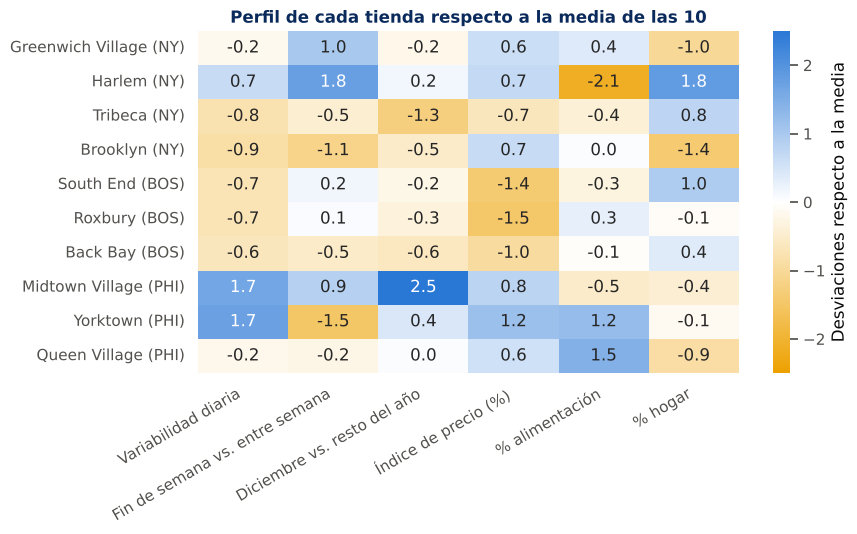

In [18]:
PERFIL_T = ['cv_daily', 'weekend_lift', 'dec_lift', 'indice_precio_pct', 'pct_supermarket', 'pct_hogar']
z = (store_feat[PERFIL_T] - store_feat[PERFIL_T].mean()) / store_feat[PERFIL_T].std()
z.index = store_feat['store'] + ' (' + store_feat['region'].map({'New York': 'NY', 'Boston': 'BOS', 'Philadelphia': 'PHI'}) + ')'

fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(z.rename(columns=ETIQUETAS), annot=True, fmt='.1f', cmap=DIVERGENTE, center=0,
            vmin=-2.5, vmax=2.5, cbar_kws={'label': 'Desviaciones respecto a la media'}, ax=ax)
ax.set_title('Perfil de cada tienda respecto a la media de las 10')
ax.set_ylabel('')
plt.xticks(rotation=30, ha='right')
plt.tight_layout()
plt.show()

### 5.3. ¿Qué tienda se parece más a cuál?

Se mide la distancia entre tiendas con las variables de **perfil** de la tabla anterior. El volumen de ventas se deja fuera porque mide el tamaño de la tienda, no su forma de vender: una tienda grande y una pequeña pueden tener el mismo perfil.

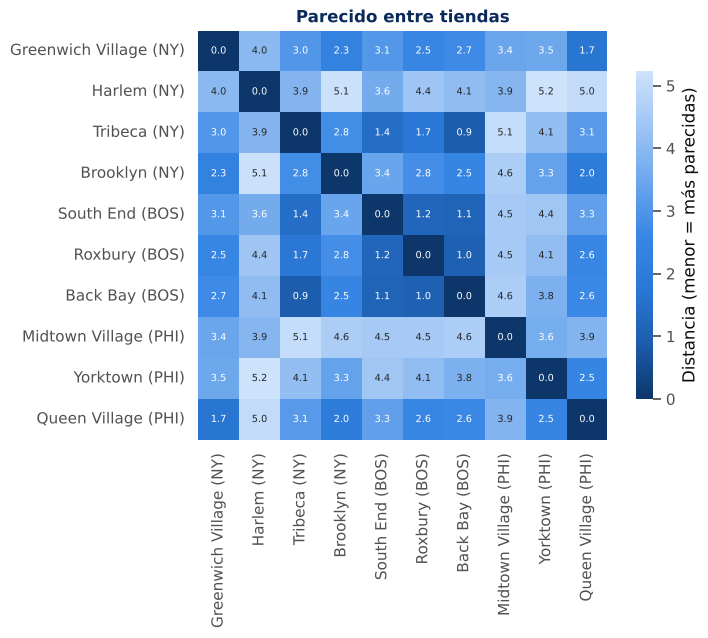

,Más parecida,Distancia,Segunda más parecida
Tienda,,,
Greenwich Village (NY),Queen Village (PHI),1.66,Brooklyn (NY)
Harlem (NY),South End (BOS),3.61,Tribeca (NY)
Tribeca (NY),Back Bay (BOS),0.90,South End (BOS)
Brooklyn (NY),Queen Village (PHI),1.98,Greenwich Village (NY)
South End (BOS),Back Bay (BOS),1.12,Roxbury (BOS)
Roxbury (BOS),Back Bay (BOS),1.01,South End (BOS)
Back Bay (BOS),Tribeca (NY),0.90,Roxbury (BOS)
Midtown Village (PHI),Greenwich Village (NY),3.45,Yorktown (PHI)
Yorktown (PHI),Queen Village (PHI),2.52,Brooklyn (NY)


In [19]:
D = pd.DataFrame(cdist(z.values, z.values), index=z.index, columns=z.index)
parecido = []
for t in D.index:
    otras = D.loc[t].drop(t).sort_values()
    parecido.append({'Tienda': t, 'Más parecida': otras.index[0], 'Distancia': otras.iloc[0],
                     'Segunda más parecida': otras.index[1]})
parecido = pd.DataFrame(parecido).set_index('Tienda')

fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(D, annot=True, fmt='.1f', cmap=dsmarket_blues_cmap.reversed(), square=True,
            cbar_kws={'label': 'Distancia (menor = más parecidas)', 'shrink': 0.8}, ax=ax, annot_kws={'size': 7})
ax.set_title('Parecido entre tiendas')
ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout()
plt.show()

# se guarda la tienda más parecida de cada una: la usan el almacén de datos y la aplicación
codigo = dict(zip(z.index, store_feat.index))
pd.DataFrame({'store_code': [codigo[t] for t in parecido.index],
              'tienda_mas_parecida': [codigo[t] for t in parecido['Más parecida']]}
             ).to_csv('cache_forecast/tienda_mas_parecida.csv', index=False)
parecido.round(2)

**Qué se ve al comparar las tiendas directamente:**

- **Tribeca (Nueva York) se parece más a las tiendas de Boston que a las de su propia ciudad.** Su tienda más parecida es Back Bay y la segunda, South End, ambas de Boston. Comparte con ellas el precio por debajo de la media (−0,39 %, frente a −0,55 % / −0,85 % en Boston y +0,36 % / +0,40 % en el resto de Nueva York), la baja variabilidad diaria y un fin de semana moderado.
- **Las tres tiendas de Boston se parecen mucho entre sí** (son las distancias más pequeñas de la tabla). Boston es la ciudad más homogénea, igual que se vio en el EDA con los productos más vendidos.
- **Harlem y Midtown Village no se parecen a ninguna otra tienda.** Harlem tiene el fin de semana más fuerte (+50 %) y el mayor peso de hogar (28 %). Midtown Village es la única tienda que vende más en diciembre que el resto del año y, junto con Yorktown, la de ventas más irregulares.
- **El precio separa por ciudad:** Boston y Tribeca son las tiendas baratas, Filadelfia la más cara. Las diferencias son menores del 1 %.

**Conclusión para Michelle:** el perfil de una tienda depende más de su barrio y de su clientela que de su ciudad. Si se abre una tienda nueva, la referencia para su surtido y su previsión inicial debería ser la tienda existente más parecida en tipo de barrio, no la media de su ciudad.

## 6. Conclusiones y uso en las siguientes tareas

| Pedido | Respuesta |
|---|---|
| ¿Cuántos grupos de productos? ¿5, 10 o 20? | **6**, elegidos con el método del codo y la silueta, y estables (ARI 0,98 entre 10 semillas). |
| ¿Qué es cada grupo? | Una ficha con nombre de negocio ligado a los productos que contiene (sección 4.6). |
| ¿Tiene sentido agrupar tiendas? | **No con un algoritmo**: 10 tiendas y más variables que tiendas. Se comparan directamente (sección 5) y aparecen los mismos hallazgos: Tribeca se comporta como Boston, y Harlem y Midtown son atípicas. |

**Decisiones de método, resumidas:**
- Todas las variables se miden **desde la primera venta** de cada producto, para no confundir un lanzamiento tardío con un producto de venta ocasional.
- 6 variables de comportamiento; se quitan `cv_daily` (repite `zero_frac`) y `trend` (describe el ciclo de vida, no el momento de compra).
- `StandardScaler`, porque `RobustScaler` aísla productos sueltos en grupos de uno.
- K-Means con K elegido por el codo (K de 2 a 14) y la silueta.

**Qué pasa a las tareas siguientes:**
- **Tarea 3 (predicción):** el grupo de producto entra como variable del modelo. Ya no se usa ningún grupo de tiendas; la tienda y la ciudad ya están en el modelo como variables propias.
- **Tarea 4 (reposición):** los grupos ayudan a describir cada producto, pero la política de reposición se decide **simulando su coste** (Tarea 4), no por el grupo ni por el error de predicción: la Tarea 4 muestra que el modelo ahorra más justo en los productos de venta irregular. El grupo 5 sí necesita una regla de temporada.

**Limitación:** la silueta es moderada (0,17) porque los productos forman un continuo y no grupos separados. Los grupos son una forma útil y estable de ordenar el catálogo, no "tipos naturales" de producto.